<a href="https://colab.research.google.com/github/gayatrishekharcs/AI_LAB/blob/main/WEEK10_1BM24CS103_ALPHA_BETA_PRUNING.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Enter leaf values separated by spaces: 2 3 5 9 0 1 7 5
Enter root type (MAX or MIN): MAX

========== RESULTS ==========
Root Type: MAX
Leaf Values: [2, 3, 5, 9, 0, 1, 7, 5]
Optimal Root Value: 3

Evaluated Nodes:
Node 0 = 3
Node 1 = 3
Node 2 = 1
Node 3 = 3
Node 4 = 5
Node 5 = 1

Pruned Nodes: [6, 10, 13, 14]
Pruned Leaf Values: [9, 7, 5]
Total Pruned Nodes: 4


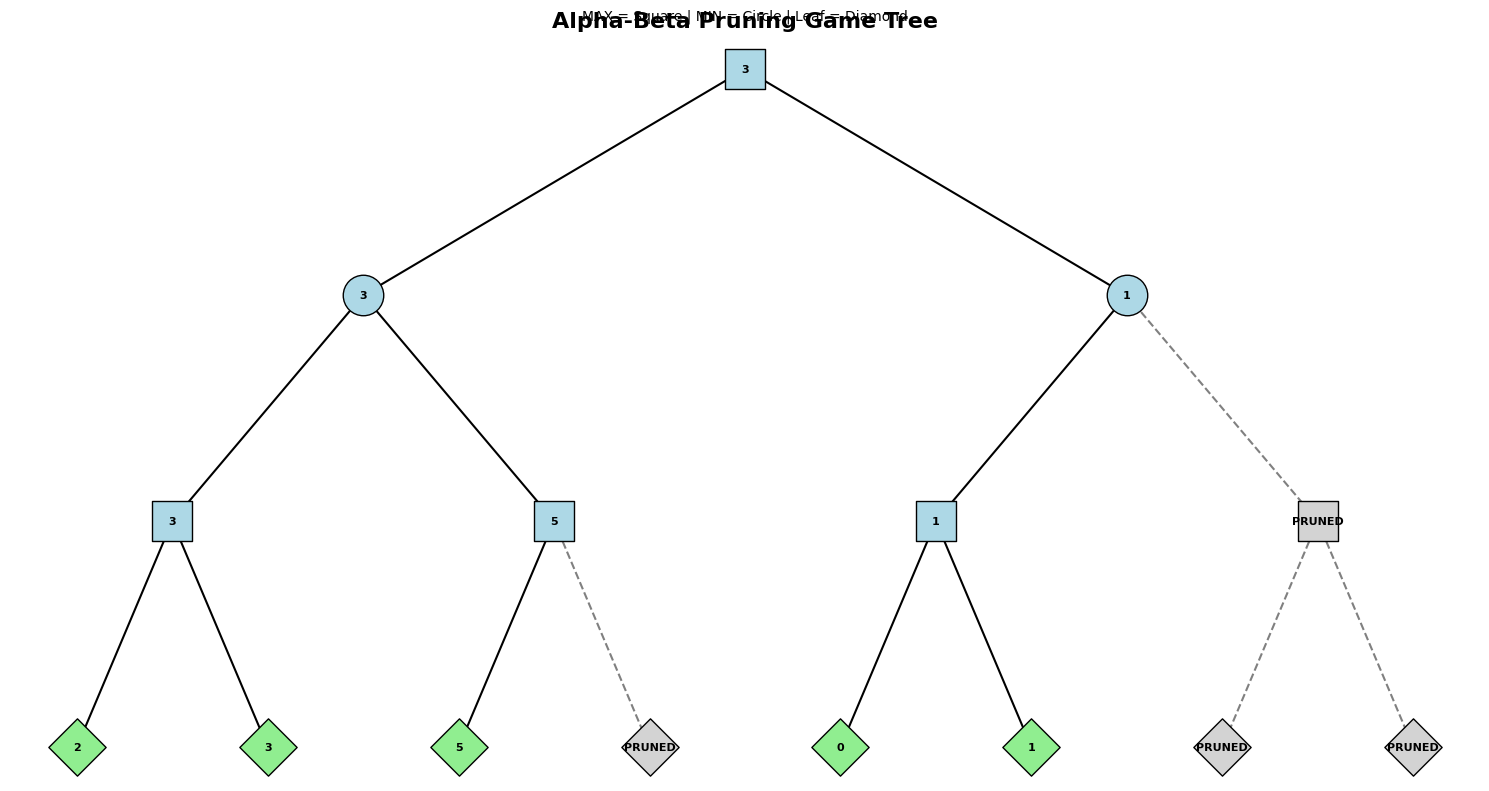

In [1]:
import math
import matplotlib.pyplot as plt

# Take input from user
values = list(map(int, input("Enter leaf values separated by spaces: ").split()))

n = len(values)

# Check whether number of leaves is a power of 2
if n == 0 or (n & (n - 1)) != 0:
    print("Error: Enter 2, 4, 8, 16, 32, ... leaf values.")
else:
    root_type = input("Enter root type (MAX or MIN): ").upper()

    if root_type not in ["MAX", "MIN"]:
        print("Invalid root type. Enter MAX or MIN.")

    else:
        total = 2 * n - 1
        depth = int(math.log2(n))

        # Create complete binary tree
        tree = [None] * total
        start = n - 1

        for i in range(n):
            tree[start + i] = values[i]

        evaluated = {}
        visited = set()
        pruned = set()

        # Get level of a node
        def get_level(node):
            return int(math.log2(node + 1))

        # Mark an entire subtree as pruned
        def mark_pruned(node):
            if node >= total:
                return

            pruned.add(node)

            mark_pruned(2 * node + 1)
            mark_pruned(2 * node + 2)

        # Alpha-Beta Pruning algorithm
        def alpha_beta(node, alpha, beta):

            visited.add(node)

            # Leaf node
            if node >= n - 1:
                return tree[node]

            level = get_level(node)

            is_max = (
                (level % 2 == 0)
                if root_type == "MAX"
                else (level % 2 == 1)
            )

            if is_max:
                best = float('-inf')

                children = [2 * node + 1, 2 * node + 2]

                for i, child in enumerate(children):
                    value = alpha_beta(child, alpha, beta)

                    best = max(best, value)
                    alpha = max(alpha, best)

                    # Pruning condition
                    if alpha >= beta:
                        for remaining in children[i + 1:]:
                            mark_pruned(remaining)
                        break

            else:
                best = float('inf')

                children = [2 * node + 1, 2 * node + 2]

                for i, child in enumerate(children):
                    value = alpha_beta(child, alpha, beta)

                    best = min(best, value)
                    beta = min(beta, best)

                    # Pruning condition
                    if alpha >= beta:
                        for remaining in children[i + 1:]:
                            mark_pruned(remaining)
                        break

            evaluated[node] = best
            return best

        # Execute algorithm
        result = alpha_beta(
            0,
            float('-inf'),
            float('inf')
        )

        print("\n========== RESULTS ==========")
        print("Root Type:", root_type)
        print("Leaf Values:", values)
        print("Optimal Root Value:", result)

        print("\nEvaluated Nodes:")
        for node, value in sorted(evaluated.items()):
            print("Node", node, "=", value)

        print("\nPruned Nodes:", sorted(pruned))

        pruned_leaves = [
            tree[i] for i in sorted(pruned)
            if i >= n - 1
        ]

        print("Pruned Leaf Values:", pruned_leaves)
        print("Total Pruned Nodes:", len(pruned))

        # =========================
        # GRAPH VISUALIZATION
        # =========================

        positions = {}

        for node in range(total):
            level = get_level(node)
            index = node - (2 ** level - 1)
            span = n / (2 ** level)

            x = index * span + span / 2
            y = -level

            positions[node] = (x, y)

        fig, ax = plt.subplots(figsize=(15, 8))

        # Draw edges
        for node in range(total):
            left = 2 * node + 1
            right = 2 * node + 2

            for child in [left, right]:
                if child < total:
                    x1, y1 = positions[node]
                    x2, y2 = positions[child]

                    if child in pruned:
                        ax.plot(
                            [x1, x2], [y1, y2],
                            color="gray",
                            linestyle="--",
                            linewidth=1.5
                        )
                    else:
                        ax.plot(
                            [x1, x2], [y1, y2],
                            color="black",
                            linewidth=1.5
                        )

        # Draw nodes
        for node in range(total):

            x, y = positions[node]
            level = get_level(node)

            if node in pruned:
                color = "lightgray"
                label = "PRUNED"

            elif node >= n - 1:
                color = "lightgreen"
                label = str(tree[node])

            else:
                color = "lightblue"
                label = str(evaluated[node])

            # MAX = square, MIN = circle, leaves = diamond
            if node >= n - 1:
                marker = "D"
            else:
                is_max = (
                    (level % 2 == 0)
                    if root_type == "MAX"
                    else (level % 2 == 1)
                )
                marker = "s" if is_max else "o"

            ax.scatter(
                x, y,
                s=850,
                marker=marker,
                color=color,
                edgecolors="black",
                zorder=3
            )

            ax.text(
                x, y,
                label,
                ha="center",
                va="center",
                fontsize=8,
                fontweight="bold",
                zorder=4
            )

        ax.set_title(
            "Alpha-Beta Pruning Game Tree",
            fontsize=16,
            fontweight="bold"
        )

        ax.text(
            0.5, 1.02,
            "MAX = Square | MIN = Circle | Leaf = Diamond",
            transform=ax.transAxes,
            ha="center",
            fontsize=10
        )

        ax.axis("off")
        plt.tight_layout()
        plt.show()

